# Function Transformer

In [3]:
import pandas as pd 
import numpy as np 

import scipy.stats as stats

import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [4]:
df = pd.read_csv('train.csv',usecols=['Age','Fare','Survived'])

In [5]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [6]:
df.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [7]:
df['Age']=df['Age'].fillna(df['Age'].mean())

In [8]:
df['Age'] = df['Age'].fillna(df['Age'].mean())


In [9]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [10]:
df.isnull().sum()

Survived    0
Age         0
Fare        0
dtype: int64

In [11]:
X=df.iloc[:,1:3]
y=df.iloc[:,0]

In [12]:
X_train, X_test, y_train , y_test = train_test_split(X,y,test_size=0.2,random_state=42)

C:\Users\vaibh\AppData\Local\Temp\ipykernel_11724\3017042154.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train['Age'])


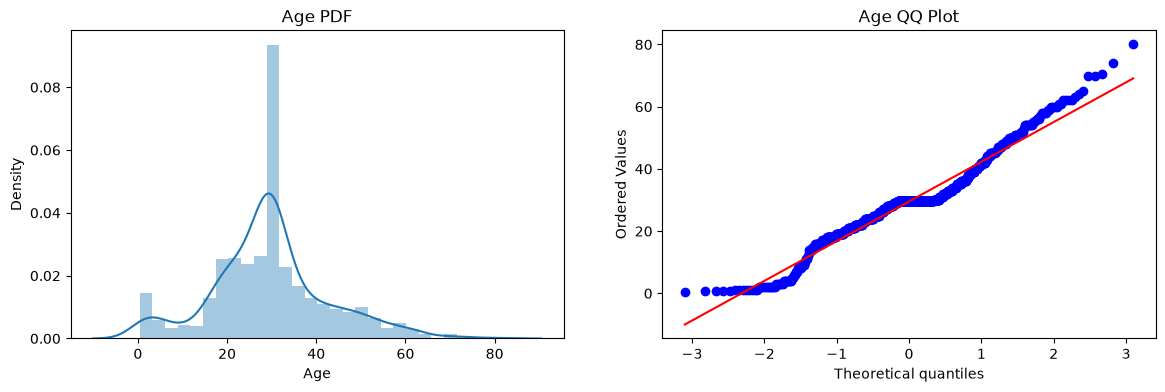

In [31]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.distplot(X_train['Age'])
plt.title('Age PDF')

plt.subplot(122)
stats.probplot(X_train['Age'],dist='norm',plot=plt)
plt.title('Age QQ Plot')

plt.show()


C:\Users\vaibh\AppData\Local\Temp\ipykernel_11724\2312468097.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train['Fare'])


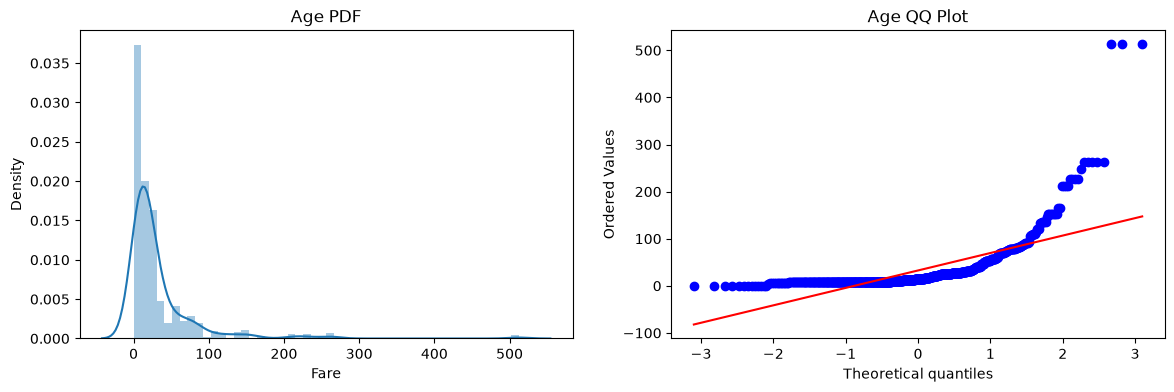

In [32]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.distplot(X_train['Fare'])
plt.title('Age PDF')

plt.subplot(122)
stats.probplot(X_train['Fare'],dist='norm',plot=plt)
plt.title('Age QQ Plot')

plt.show()

In [33]:
clf= LogisticRegression()
clf2=DecisionTreeClassifier()

In [34]:
clf.fit(X_train,y_train)
clf2.fit(X_train,y_train)

y_pred = clf.predict(X_test)
y_pred1= clf2.predict(X_test)

print('Accuracy LR',accuracy_score(y_test,y_pred))
print('Accuracy DT',accuracy_score(y_test,y_pred1))

Accuracy LR 0.6480446927374302
Accuracy DT 0.6480446927374302


In [35]:
trf = FunctionTransformer(func=np.log1p)

In [36]:
X_train_transformed = trf.fit_transform(X_train)
X_test_transformed = trf.transform(X_test)

In [37]:
X_train_transformed

,Age,Fare
331,3.839452,3.384390
733,3.178054,2.639057
382,3.496508,2.188856
704,3.295837,2.180892
813,1.945910,3.474293
...,...,...
106,3.091042,2.157559
270,3.424234,3.465736
860,3.737670,2.715244
435,2.708050,4.795791


In [38]:
X_test_transformed

,Age,Fare
709,3.424234,2.787834
439,3.465736,2.442347
840,3.044522,2.188856
720,1.945910,3.526361
39,2.708050,2.504848
...,...,...
433,2.890372,2.094946
773,3.424234,2.107178
25,3.663562,3.477773
84,2.890372,2.442347


In [39]:
clf= LogisticRegression()
clf2=DecisionTreeClassifier()

clf.fit(X_train_transformed,y_train)
clf2.fit(X_train_transformed,y_train)

y_pred = clf.predict(X_test_transformed)
y_pred1= clf2.predict(X_test_transformed)

print('Accuracy LR',accuracy_score(y_test,y_pred))
print('Accuracy DT',accuracy_score(y_test,y_pred1))

Accuracy LR 0.6815642458100558
Accuracy DT 0.6815642458100558


In [40]:
X_transformed = trf.fit_transform(X)
clf= LogisticRegression()
clf2=DecisionTreeClassifier()

print('LR',np.mean(cross_val_score(clf,X_transformed,y,scoring='accuracy',cv= 10)))
print('DT',np.mean(cross_val_score(clf2,X_transformed,y,scoring='accuracy',cv= 10)))

LR 0.678027465667915
DT 0.6588639200998753


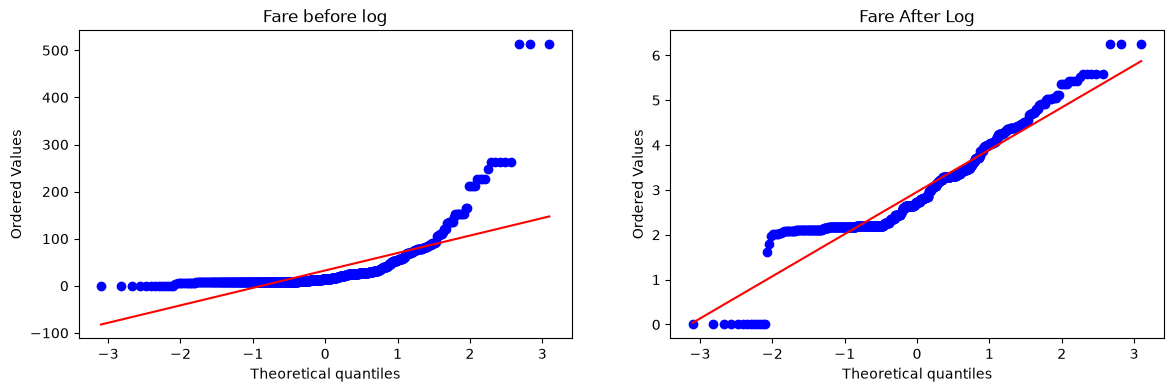

In [41]:
plt.figure(figsize=(14,4))
plt.subplot(121)
stats.probplot(X_train['Fare'],dist='norm',plot=plt)
plt.title('Fare before log')

plt.subplot(122)
stats.probplot(X_train_transformed['Fare'],dist='norm',plot=plt)
plt.title('Fare After Log')

plt.show()









# plt.figure(figsize=(14, 4))

# # Subplot 1: Before Log
# plt.subplot(121)
# stats.probplot(X_train['Fare'], dist='norm', plot=plt)  # Changed sns to stats
# plt.title('Fare before log')

# # Subplot 2: After Log
# plt.subplot(122)
# stats.probplot(X_train_transformed['Fare'], dist='norm', plot=plt)
# plt.title('Fare After Log')

# plt.show()

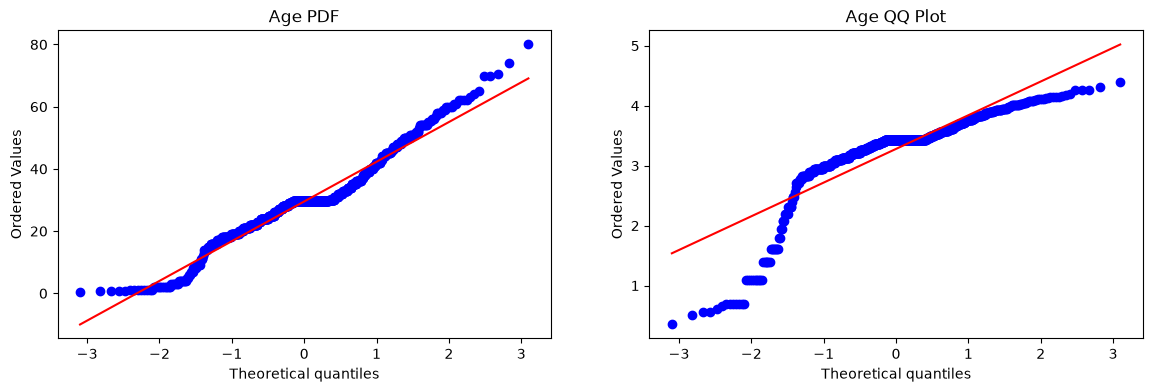

In [42]:
plt.figure(figsize=(14,4))
plt.subplot(121)
stats.probplot(X_train['Age'],dist='norm',plot=plt)
plt.title('Age PDF')

plt.subplot(122)
stats.probplot(X_train_transformed['Age'],dist='norm',plot=plt)
plt.title('Age QQ Plot')

plt.show()








# plt.figure(figsize=(14, 4))

# # Subplot 1: Before Log
# plt.subplot(121)
# stats.probplot(X_train['Age'], dist='norm', plot=plt)  # Changed sns to stats
# plt.title('Fare before log')

# # Subplot 2: After Log
# plt.subplot(122)
# stats.probplot(X_train_transformed['Age'], dist='norm', plot=plt)
# plt.title('Fare After Log')

# plt.show()

In [43]:
trf2 = ColumnTransformer([('log',FunctionTransformer(np.log1p),['Fare'])],remainder='passthrough')

X_train_transformed2= trf2.fit_transform(X_train)
X_test_transformed2 = trf2.transform(X_test)

In [44]:
clf.fit(X_train_transformed2,y_train)
clf2.fit(X_train_transformed2,y_train)

y_pred = clf.predict(X_test_transformed2)
y_pred2= clf2.predict(X_test_transformed2)

print('Accuracy LR',accuracy_score(y_test,y_pred))
print('Accuracy DT',accuracy_score(y_test,y_pred2))

Accuracy LR 0.6703910614525139
Accuracy DT 0.6536312849162011


In [45]:
X_transformed2 = trf.fit_transform(X)
clf= LogisticRegression()
clf2=DecisionTreeClassifier()

print('LR',np.mean(cross_val_score(clf,X_transformed2,y,scoring='accuracy',cv= 10)))
print('DT',np.mean(cross_val_score(clf2,X_transformed2,y,scoring='accuracy',cv= 10)))

LR 0.678027465667915
DT 0.6622097378277153


In [46]:
def apply_transform(transform):
    x=df.iloc[:,1:3]
    y=df.iloc[:,0]

    trf = ColumnTransformer([('log',FunctionTransformer(transform),['Fare'])],remainder='passthrough')

    X_trans = trf.fit_transform(X)

    clf = LogisticRegression()

    print("Accuracy",np.mean(cross_val_score(clf,X_trans, y ,scoring='accuracy',cv=10)))

    plt.figure(figsize=(14,4))

    plt.subplot(121)
    stats.probplot(X['Fare'],dist='norm',plot=plt)
    plt.title('fare before Transform')

    plt.subplot(122)
    stats.probplot(X_trans[:,0],dist='norm', plot=plt)
    plt.title('Fare after transform')

    plt.show()

Accuracy 0.6589013732833957


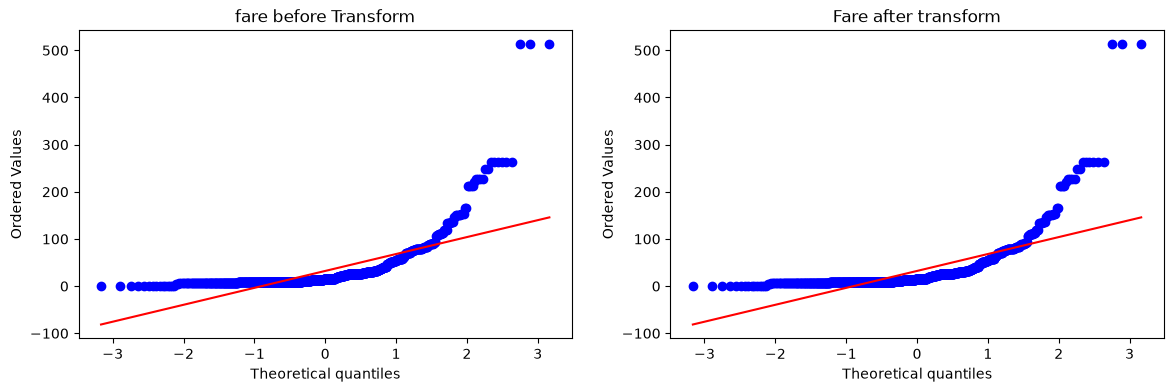

In [47]:
apply_transform(lambda x: x)

Accuracy 0.61729088639201


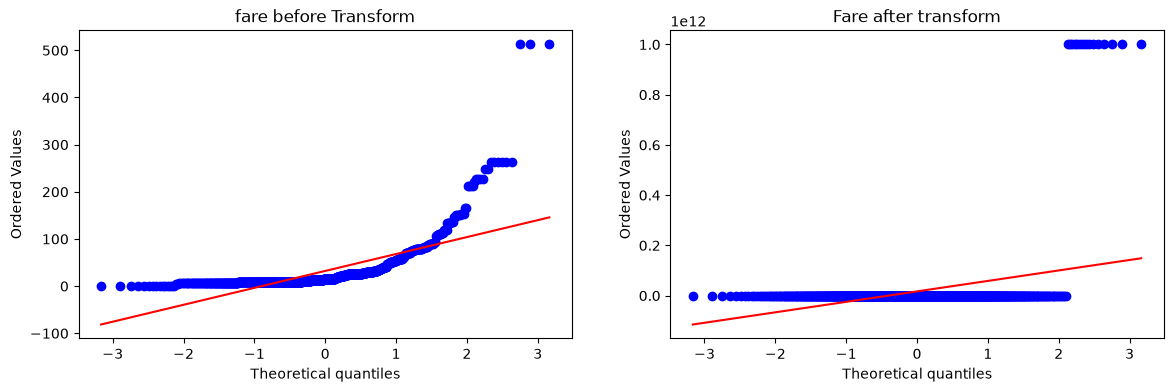

In [48]:
apply_transform(lambda x: 1/(x+0.000000000001))